# Taller MLOps · Calidad del vino tinto con gobernanza (ISO/IEC 42001 + CRISP-ML(Q))

Este cuaderno adapta el ejemplo clásico *Red Wine Quality Model* a un flujo de trabajo de MLOps, pensado para ejecutarse **en local, en WSL2 (Ubuntu) con VS Code**.

**Objetivos de aprendizaje**

1. Recorrer las fases de CRISP-ML(Q) de forma explícita.
2. Evitar fugas de información (*data leakage*) en la preparación y en la validación cruzada.
3. Registrar experimentos, parámetros y métricas con **MLflow**.
4. Generar evidencias documentales (trazabilidad de datos, versiones y métricas) alineadas con la gestión de sistemas de IA.

**Mapa de fases**

| Fase CRISP-ML(Q) | Secciones de este cuaderno |
|---|---|
| 1. Entendimiento del negocio | Contexto y variables |
| 2. Entendimiento y preparación de datos | Carga, calidad de datos, EDA |
| 3. Ingeniería de características | Binarización del objetivo, división, escalado y PCA |
| 4. Modelado | Comparación de modelos con MLflow |
| 5. Evaluación | Validación cruzada, búsqueda de hiperparámetros, prueba final |
| 6. Despliegue y monitoreo | Modelo persistido y evidencias de gobernanza |

> Material didáctico. Los controles de ISO/IEC 42001 se mencionan como referencia; verifícalos contra el texto vigente de la norma.

---

## Contexto del problema

Los datos corresponden a variantes tinta y blanca del "Vinho Verde" portugués (Cortez et al., 2009). Solo se dispone de variables fisicoquímicas (entradas) y de una puntuación sensorial (salida); no hay información de uva, marca o precio.

**Variables de entrada (fisicoquímicas):** acidez fija, acidez volátil, ácido cítrico, azúcar residual, cloruros, dióxido de azufre libre, dióxido de azufre total, densidad, pH, sulfatos y alcohol.

**Variable de salida:** `quality`, una puntuación entre 0 y 10.

**Planteamiento de este taller:** convertir la calidad en un problema de clasificación binaria. Los vinos con calidad mayor a 6.5 (es decir, 7 u 8) se consideran **buenos (1)** y el resto **no buenos (0)**. Las clases están desbalanceadas, así que observaremos métricas más allá de la exactitud.

## 0. Preparación del entorno

In [1]:
# Importación de librerías
import os
import sys
import json
import random
import hashlib
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import requests

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay)
import mlflow
import mlflow.sklearn

%matplotlib inline
sns.set_theme(style="whitegrid")

/home/adiaz/taller-mlops-vino/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Parámetros del experimento: se leen de params.yaml (única fuente de verdad)
# Para cambiar un parámetro, edita params.yaml y ejecuta de nuevo (o usa `dvc repro`)
import yaml

# Rutas: el cuaderno vive en notebooks/, la raíz del proyecto es su carpeta padre
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RUTA_PARAMS = RAIZ / "params.yaml"
with open(RUTA_PARAMS, encoding="utf-8") as f:
    P = yaml.safe_load(f)["taller"]

random.seed(P["random_state"])
np.random.seed(P["random_state"])

for carpeta in ["data/raw", "models", "governance"]:
    (RAIZ / carpeta).mkdir(parents=True, exist_ok=True)

print("Raíz del proyecto:", RAIZ)
print("Parámetros leídos de", RUTA_PARAMS.name, ":", json.dumps(P, indent=2, ensure_ascii=False))


Raíz del proyecto: /home/adiaz/taller-mlops-vino
Parámetros leídos de params.yaml : {
  "random_state": 100,
  "test_size": 0.2,
  "umbral_calidad": 6.5,
  "eliminar_duplicados": true,
  "pca_components": 4,
  "cv_folds": 10,
  "experimento_mlflow": "vino-calidad-iso42001V2"
}


In [3]:
# Comprobación del entorno: el kernel debe ser el de .venv del proyecto
print("Ejecutable de Python:", sys.executable)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| sklearn:", sklearn.__version__)
print("mlflow:", mlflow.__version__)

Ejecutable de Python: /home/adiaz/taller-mlops-vino/.venv/bin/python3
Python: 3.14.4
pandas: 3.1.1 | numpy: 2.5.5 | sklearn: 1.9.1
mlflow: 3.18.0


## 1. Carga de datos

El archivo `winequality-red.csv` debe estar en `data/raw/`. Si no existe y hay conexión a Internet, se descarga desde el repositorio de la UCI.

> **Nota:** el archivo original de la UCI usa **punto y coma** (`;`) como separador, no coma. El código lo detecta automáticamente.

In [4]:
RUTA_DATOS = RAIZ / "data" / "raw" / "winequality-red.csv"
URL_UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

if not RUTA_DATOS.exists():
    try:
        print("Descargando datos desde la UCI...")
        r = requests.get(URL_UCI, timeout=30)
        r.raise_for_status()
        RUTA_DATOS.write_bytes(r.content)
    except Exception as e:
        raise FileNotFoundError(
            f"No se encontró {RUTA_DATOS} y la descarga falló ({e}). "
            "Coloca winequality-red.csv en data/raw/ y vuelve a ejecutar."
        )

# Detección del separador
with open(RUTA_DATOS, encoding="utf-8") as f:
    primera_linea = f.readline()
separador = ";" if ";" in primera_linea else ","

wine = pd.read_csv(RUTA_DATOS, sep=separador)
print(f"Archivo: {RUTA_DATOS.name} | separador: '{separador}' | filas: {len(wine)} | columnas: {wine.shape[1]}")
wine.head()

Archivo: winequality-red.csv | separador: ',' | filas: 1599 | columnas: 12


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
# Hash del archivo de datos: permite demostrar después que se usó exactamente el mismo conjunto
hash_datos = hashlib.sha256(RUTA_DATOS.read_bytes()).hexdigest()
print("SHA-256 de los datos crudos:", hash_datos)

SHA-256 de los datos crudos: b7e0f7ea223f5926ce61bcc34654f7ed4c62d9559f87e16c9bd28f772deed74d


## 2. Calidad de datos y análisis exploratorio (EDA)

In [6]:
print("Valores nulos por columna:")
print(wine.isna().sum())
print()
print("Filas duplicadas:", wine.duplicated().sum())
wine.info()

Valores nulos por columna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Filas duplicadas: 240
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH            

**Discusión para los estudiantes:** las filas duplicadas pueden inflar las métricas, porque el mismo vino aparece en entrenamiento y en prueba. Por eso el parámetro `eliminar_duplicados` está activo. Cambiarlo a `False` permite comparar el efecto (la versión *v1 con duplicados* del flujo de versiones del taller).

In [7]:
n_antes = len(wine)
if P["eliminar_duplicados"]:
    wine = wine.drop_duplicates().reset_index(drop=True)
duplicados_eliminados = n_antes - len(wine)
print(f"Filas antes: {n_antes} | después: {len(wine)} | duplicados eliminados: {duplicados_eliminados}")

Filas antes: 1599 | después: 1359 | duplicados eliminados: 240


In [8]:
wine[wine.columns[:11]].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.310596,1.736990,4.60000,7.1000,7.9000,9.20000,15.90000
volatile acidity,1359.0,0.529478,0.183031,0.12000,0.3900,0.5200,0.64000,1.58000
citric acid,1359.0,0.272333,0.195537,0.00000,0.0900,0.2600,0.43000,1.00000
residual sugar,1359.0,2.523400,1.352314,0.90000,1.9000,2.2000,2.60000,15.50000
chlorides,1359.0,0.088124,0.049377,0.01200,0.0700,0.0790,0.09100,0.61100
free sulfur dioxide,1359.0,15.893304,10.447270,1.00000,7.0000,14.0000,21.00000,72.00000
total sulfur dioxide,1359.0,46.825975,33.408946,6.00000,22.0000,38.0000,63.00000,289.00000
density,1359.0,0.996709,0.001869,0.99007,0.9956,0.9967,0.99782,1.00369
pH,1359.0,3.309787,0.155036,2.74000,3.2100,3.3100,3.40000,4.01000
sulphates,1359.0,0.658705,0.170667,0.33000,0.5500,0.6200,0.73000,2.00000


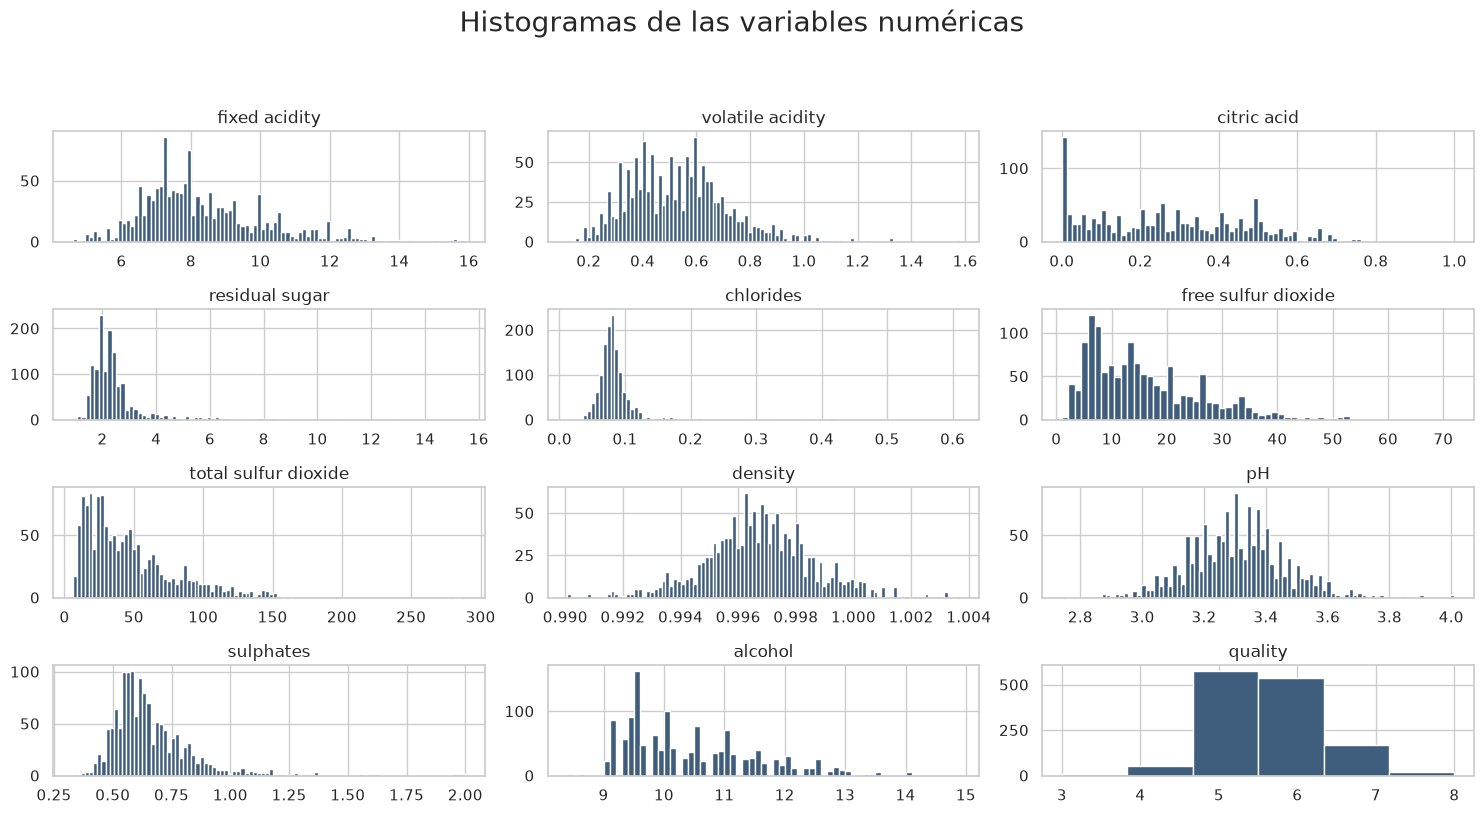

In [9]:
# Histogramas de las variables numéricas
fig = plt.figure(figsize=(15, 12))
plt.suptitle("Histogramas de las variables numéricas", fontsize=20)
for i in range(wine.shape[1]):
    plt.subplot(6, 3, i + 1)
    plt.gca().set_title(wine.columns[i])
    vals = min(np.size(wine.iloc[:, i].unique()), 100)
    plt.hist(wine.iloc[:, i], bins=vals, color="#3F5D7D")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

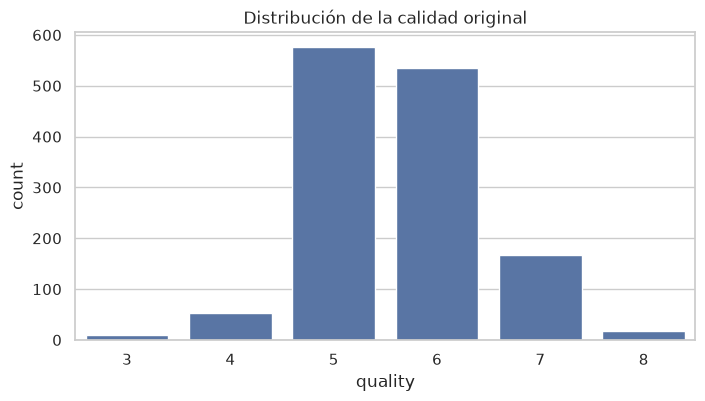

In [10]:
# Distribución de la calidad original (0 a 10)
plt.figure(figsize=(8, 4))
sns.countplot(x=wine["quality"])
plt.title("Distribución de la calidad original")
plt.show()

## 3. Ingeniería de características y objetivo binario

Distribución del objetivo binario (0 = no bueno, 1 = bueno):
quality
0    1175
1     184
Name: count, dtype: int64


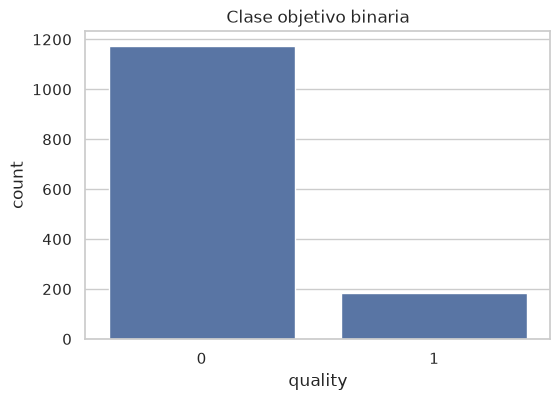

In [11]:
# Binarización del objetivo: 3-6 => 0 (no bueno), 7-8 => 1 (bueno)
# labels=False devuelve directamente los códigos 0 y 1 según el orden de los intervalos
# (no usar LabelEncoder aquí: ordena alfabéticamente y puede invertir las clases)
bins = (2, P["umbral_calidad"], 8)
wine["calidad_original"] = wine["quality"]           # se conserva solo para el EDA
wine["quality"] = pd.cut(wine["quality"], bins=bins, labels=False).astype(int)

# Verificación: la clase 1 debe corresponder a calidades mayores al umbral
assert wine.loc[wine["quality"] == 1, "calidad_original"].min() > P["umbral_calidad"]
assert wine.loc[wine["quality"] == 0, "calidad_original"].max() <= P["umbral_calidad"]

print("Distribución del objetivo binario (0 = no bueno, 1 = bueno):")
print(wine["quality"].value_counts())
plt.figure(figsize=(6, 4))
sns.countplot(x=wine["quality"])
plt.title("Clase objetivo binaria")
plt.show()

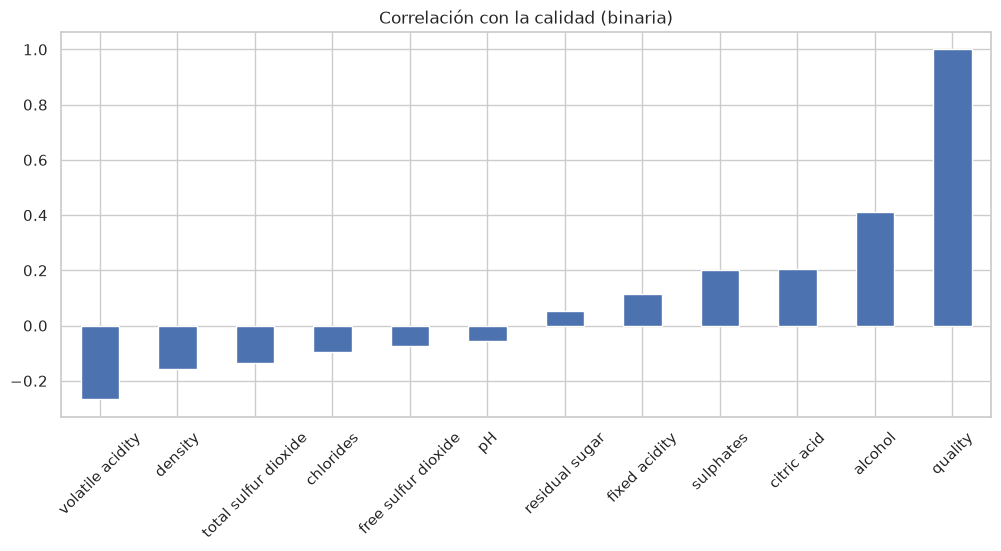

In [12]:
# Correlación de cada variable con el objetivo binario
wine.drop(columns="calidad_original").corrwith(wine["quality"]).sort_values().plot.bar(
    figsize=(12, 5), title="Correlación con la calidad (binaria)", fontsize=11, rot=45, grid=True)
plt.show()

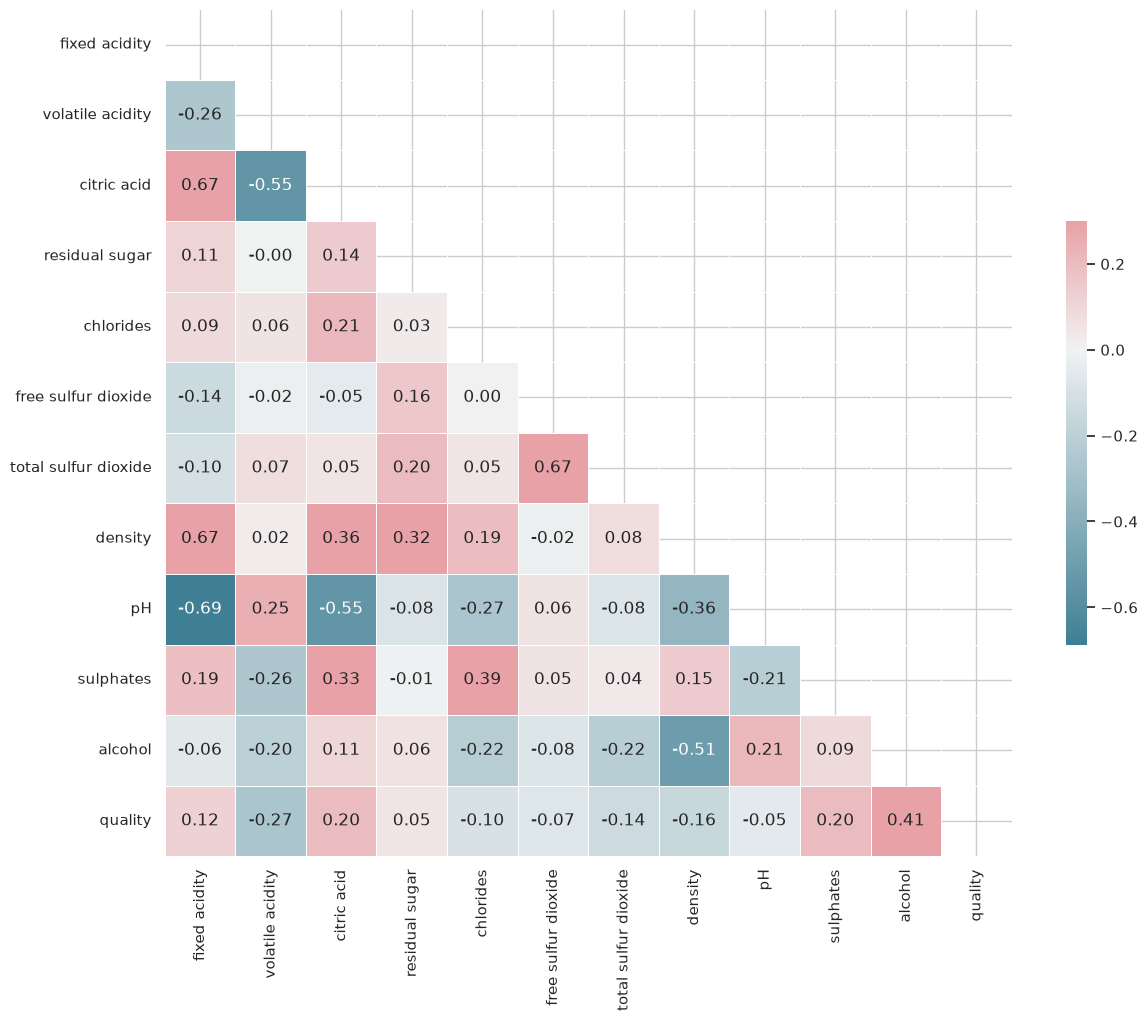

In [13]:
# Matriz de correlación
corr = wine.drop(columns="calidad_original").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
f, ax = plt.subplots(figsize=(14, 11))
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=0.3, center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.5}, annot=True, fmt=".2f")
plt.show()

**Prevención de fugas:** las columnas de la variable objetivo y el resto de transformaciones (escalado y PCA) se ajustan **solo con el conjunto de entrenamiento**. Para que esto ocurra de forma automática, usamos un `Pipeline` de scikit-learn: en la validación cruzada, cada *fold* aprende su propio escalado y su propia PCA.

In [14]:
# Separación de variables predictoras y objetivo
X = wine.drop(columns=["quality", "calidad_original"])
y = wine["quality"]
print("Forma de X:", X.shape, "| forma de y:", y.shape)

# División estratificada para conservar la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=P["test_size"], random_state=5, stratify=y)
print("Entrenamiento:", X_train.shape, "| prueba:", X_test.shape)
print("Proporción de 'bueno' en entrenamiento:", round(y_train.mean(), 3),
      "| en prueba:", round(y_test.mean(), 3))

Forma de X: (1359, 11) | forma de y: (1359,)
Entrenamiento: (1087, 11) | prueba: (272, 11)
Proporción de 'bueno' en entrenamiento: 0.135 | en prueba: 0.136


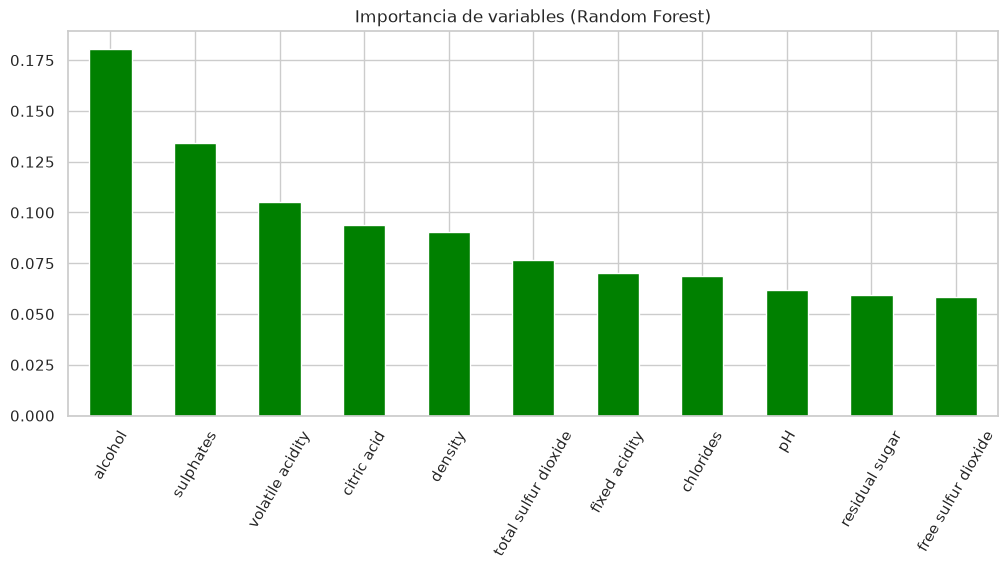

alcohol                 0.180525
sulphates               0.134376
volatile acidity        0.105407
citric acid             0.093721
density                 0.090629
total sulfur dioxide    0.076587
fixed acidity           0.070031
chlorides               0.068862
pH                      0.061744
residual sugar          0.059492
free sulfur dioxide     0.058628
dtype: float64

In [15]:
# Importancia de variables (ajustada SOLO con entrenamiento)
rf_importancia = RandomForestClassifier(n_estimators=200, criterion="entropy", random_state=0)
rf_importancia.fit(X_train, y_train)

importancias = pd.Series(rf_importancia.feature_importances_, index=X.columns).sort_values(ascending=False)
importancias.plot.bar(figsize=(12, 5), color="green", title="Importancia de variables (Random Forest)")
plt.xticks(rotation=60)
plt.show()
importancias

In [16]:
# Construcción del pipeline base: escalado -> PCA -> modelo
def construir_pipeline(modelo):
    return Pipeline([
        ("escalado", StandardScaler()),
        ("pca", PCA(n_components=P["pca_components"], random_state=P["random_state"])),
        ("clf", modelo),
    ])

# Varianza explicada por las componentes (PCA ajustada solo con entrenamiento)
_esc = StandardScaler().fit(X_train)
_pca = PCA(n_components=P["pca_components"]).fit(_esc.transform(X_train))
varianza = _pca.explained_variance_ratio_
print("Varianza explicada por componente:", np.round(varianza, 3), "| total:", round(varianza.sum(), 3))

Varianza explicada por componente: [0.283 0.173 0.138 0.11 ] | total: 0.704


## 4. Modelado y seguimiento de experimentos con MLflow

**MLflow** registra cada corrida con sus parámetros y métricas. Si el servidor está activo en `http://localhost:5000` (ver `scripts/02_iniciar_servicios.sh`), los experimentos se guardan allí; si no, se guardan en la carpeta local `mlruns/`.

In [17]:
def configurar_mlflow():
    uri = os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000")
    try:
        requests.get(uri, timeout=2)
        mlflow.set_tracking_uri(uri)
        destino = uri
    except Exception:
        # MLflow 3.x ya no admite el almacenamiento por archivos; se usa SQLite local
        destino = "sqlite:///" + str(RAIZ / "mlflow.db")
        mlflow.set_tracking_uri(destino)
    mlflow.set_experiment(P["experimento_mlflow"])
    print("Seguimiento de MLflow en:", destino)
    print("Nota: sin servidor activo, las corridas se guardan en mlflow.db (SQLite).")

configurar_mlflow()

2026/11/16 22:28:11 INFO mlflow.tracking.fluent: Experiment with name 'vino-calidad-iso42001V2' does not exist. Creating a new experiment.


Seguimiento de MLflow en: http://localhost:5000
Nota: sin servidor activo, las corridas se guardan en mlflow.db (SQLite).


In [18]:
def evaluar(pipe, X_ev, y_ev):
    # Métricas de clasificación; ROC AUC usa probabilidades o la función de decisión
    y_pred = pipe.predict(X_ev)
    if hasattr(pipe, "predict_proba"):
        puntuacion = pipe.predict_proba(X_ev)[:, 1]
    else:
        puntuacion = pipe.decision_function(X_ev)
    return {
        "accuracy": accuracy_score(y_ev, y_pred),
        "precision": precision_score(y_ev, y_pred, zero_division=0),
        "recall": recall_score(y_ev, y_pred, zero_division=0),
        "f1": f1_score(y_ev, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_ev, puntuacion),
    }

modelos = {
    "Regresión logística (L1)": LogisticRegression(random_state=0, penalty="l1", solver="liblinear", max_iter=1000),
    "SVM (lineal)": SVC(random_state=0, kernel="linear"),
    "SVM (RBF)": SVC(random_state=0, kernel="rbf"),
    "Random Forest (n=100, entropía)": RandomForestClassifier(random_state=0, n_estimators=100, criterion="entropy"),
}

filas = []
for nombre, modelo in modelos.items():
    pipe = construir_pipeline(modelo)
    with mlflow.start_run(run_name=nombre):
        pipe.fit(X_train, y_train)
        metricas = evaluar(pipe, X_test, y_test)
        mlflow.log_params({**P, "modelo": nombre})
        # Hiperparámetros del clasificador (todos los que tenga el modelo)
        mlflow.log_params({f"clf__{k}": v for k, v in modelo.get_params().items()})
        mlflow.log_metrics(metricas)
    filas.append({"Modelo": nombre, **{k: round(v, 4) for k, v in metricas.items()}})

resultados = pd.DataFrame(filas).sort_values("roc_auc", ascending=False).reset_index(drop=True)
resultados

/home/adiaz/taller-mlops-vino/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/adiaz/taller-mlops-vino/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


🏃 View run Regresión logística (L1) at: http://localhost:5000/#/experiments/3/runs/8ecdc539a6ee4fc5ba800fc7808b9f9e
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run SVM (lineal) at: http://localhost:5000/#/experiments/3/runs/81270b7a5b8d4ebaa89f03e90479d1f3
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run SVM (RBF) at: http://localhost:5000/#/experiments/3/runs/95723f962c4d46688eae636e705522c0
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run Random Forest (n=100, entropía) at: http://localhost:5000/#/experiments/3/runs/724391aacb314f85a2653b6eb04ecde8
🧪 View experiment at: http://localhost:5000/#/experiments/3


,Modelo,accuracy,precision,recall,f1,roc_auc
0,SVM (lineal),0.8640,0.0000,0.0000,0.0000,0.8621
1,Regresión logística (L1),0.8750,0.5882,0.2703,0.3704,0.8615
2,"Random Forest (n=100, entropía)",0.8676,0.5217,0.3243,0.4000,0.8055
3,SVM (RBF),0.8713,0.6250,0.1351,0.2222,0.7249


**Pregunta para discutir:** ¿por qué el modelo con mejor exactitud no siempre es el de mejor F1 o AUC? Revisa la columna `recall`: en este problema, ¿qué error es más costoso, dejar pasar un vino bueno o marcar uno malo como bueno?

## 5. Evaluación: validación cruzada y búsqueda de hiperparámetros

In [19]:
# Validación cruzada estratificada sobre el mejor modelo base (Random Forest)
pipe_rf = construir_pipeline(RandomForestClassifier(random_state=0, n_estimators=100, criterion="entropy"))
cv = StratifiedKFold(n_splits=P["cv_folds"], shuffle=True, random_state=P["random_state"])
exactitudes = cross_val_score(pipe_rf, X_train, y_train, cv=cv, scoring="accuracy")
print(f"Random Forest — exactitud CV ({P['cv_folds']} folds): {exactitudes.mean():.3f} (± {exactitudes.std() * 2:.3f})")

Random Forest — exactitud CV (10 folds): 0.884 (± 0.054)


In [20]:
# Búsqueda de hiperparámetros (ronda 1 del cuaderno original, criterio Gini)
# Los parámetros del clasificador llevan el prefijo 'clf__' porque están dentro del Pipeline
param_grid = {
    "clf__max_depth": [3, None],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 5, 10],
    "clf__bootstrap": [True, False],
    "clf__criterion": ["gini"],
}

grid = GridSearchCV(estimator=construir_pipeline(RandomForestClassifier(random_state=0, n_estimators=100)),
                    param_grid=param_grid, scoring="accuracy", cv=cv, n_jobs=-1)

t0 = time.time()
grid.fit(X_train, y_train)
print(f"Búsqueda completada en {time.time() - t0:.1f} s")
print("Mejor exactitud CV:", round(grid.best_score_, 4))
print("Mejores parámetros:", grid.best_params_)

Búsqueda completada en 13.2 s
Mejor exactitud CV: 0.8822
Mejores parámetros: {'clf__bootstrap': True, 'clf__criterion': 'gini', 'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 2}


In [21]:
# Registro de la búsqueda en MLflow: la rejilla, el mejor resultado y cada combinación probada
# Cada combinación queda como corrida hija (anidada) para compararlas en la interfaz
cv_res = pd.DataFrame(grid.cv_results_)

with mlflow.start_run(run_name="busqueda-hiperparametros"):
    mlflow.log_params({**P, "scoring": "accuracy"})
    mlflow.log_param("param_grid", json.dumps(param_grid, ensure_ascii=False))
    mlflow.log_params({f"mejor_{k}": v for k, v in grid.best_params_.items()})
    mlflow.log_metric("mejor_exactitud_cv", float(grid.best_score_))
    mlflow.log_text(cv_res.drop(columns=["params"]).to_csv(index=False), "cv_results.csv")

    for idx, fila in cv_res.iterrows():
        with mlflow.start_run(run_name=f"candidato-{idx:02d}", nested=True):
            mlflow.log_params({k.replace("clf__", ""): v for k, v in fila["params"].items()})
            mlflow.log_metrics({
                "exactitud_cv_media": float(fila["mean_test_score"]),
                "exactitud_cv_std": float(fila["std_test_score"]),
                "ranking": int(fila["rank_test_score"]),
            })
print(f"Registradas {len(cv_res)} combinaciones en MLflow")

🏃 View run candidato-00 at: http://localhost:5000/#/experiments/3/runs/c9352198c5df423883c6a6e1c201ea72
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run candidato-01 at: http://localhost:5000/#/experiments/3/runs/8e541238bbb4450d8b9e54752c9dace2
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run candidato-02 at: http://localhost:5000/#/experiments/3/runs/022986bc0e024bb387b8d027927c5d3b
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run candidato-03 at: http://localhost:5000/#/experiments/3/runs/99ad8e40478e4c059ae8106178c4cdc2
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run candidato-04 at: http://localhost:5000/#/experiments/3/runs/df0a383daf2547649f10a8aa7b302454
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run candidato-05 at: http://localhost:5000/#/experiments/3/runs/d991218445354959a5b31c15159fa153
🧪 View experiment at: http://localhost:5000/#/experiments/3


... (26 outputs left out)

🏃 View run candidato-32 at: http://localhost:5000/#/experiments/3/runs/708f7653aff4438ea980ff8bc2367a47
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run candidato-33 at: http://localhost:5000/#/experiments/3/runs/83b65fcc0aea4eb7b1d7152868e1ddaf
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run candidato-34 at: http://localhost:5000/#/experiments/3/runs/589623ddc6b4466eaa995cb9b37437be
🧪 View experiment at: http://localhost:5000/#/experiments/3


🏃 View run candidato-35 at: http://localhost:5000/#/experiments/3/runs/9dea9d4a60bc4a1d831b26b858ed4c6f
🧪 View experiment at: http://localhost:5000/#/experiments/3
🏃 View run busqueda-hiperparametros at: http://localhost:5000/#/experiments/3/runs/e73e7e6a3f3d48f894c572b99803e930
🧪 View experiment at: http://localhost:5000/#/experiments/3
Registradas 36 combinaciones en MLflow


**Nota didáctica:** el cuaderno original hacía dos rondas de búsqueda (entropía y Gini, y luego un segundo ajuste). Aquí se conserva la ronda ganadora. Un buen ejercicio es añadir una ronda con `criterion="entropy"` y comparar.

## 6. Resultados finales en el conjunto de prueba

{'accuracy': 0.864, 'precision': 0.5, 'recall': 0.2162, 'f1': 0.3019, 'roc_auc': 0.8245}


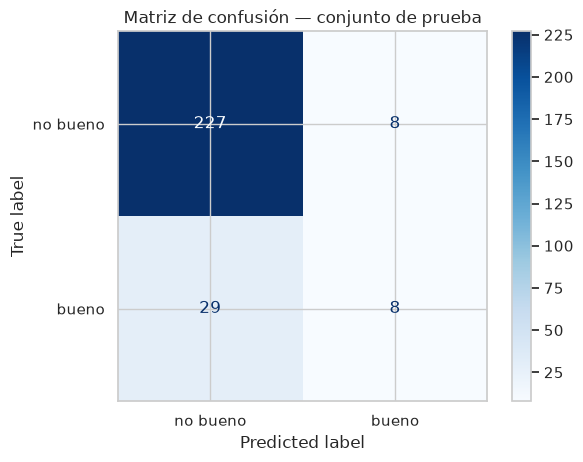

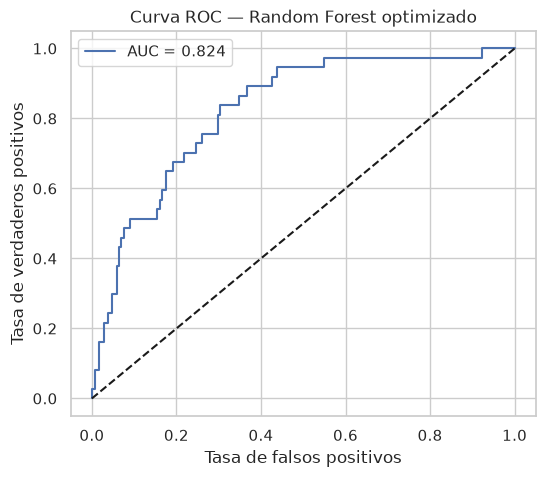

In [22]:
mejor_pipe = grid.best_estimator_
metricas_finales = evaluar(mejor_pipe, X_test, y_test)
print({k: round(v, 4) for k, v in metricas_finales.items()})

# Matriz de confusión
ConfusionMatrixDisplay.from_estimator(mejor_pipe, X_test, y_test,
                                      display_labels=["no bueno", "bueno"], cmap="Blues")
plt.title("Matriz de confusión — conjunto de prueba")
plt.show()

# Curva ROC
puntuacion = mejor_pipe.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, puntuacion)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {metricas_finales['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — Random Forest optimizado")
plt.legend()
plt.show()

## 7. Despliegue, registro del modelo y evidencias de gobernanza

In [23]:
# 7.1 Persistir el pipeline completo (escalado + PCA + modelo) para inferencia
RUTA_MODELO = RAIZ / "models" / "modelo_vino.joblib"
joblib.dump(mejor_pipe, RUTA_MODELO)
print("Modelo guardado en:", RUTA_MODELO)

# 7.2 Registrar el modelo final en MLflow
with mlflow.start_run(run_name="modelo-final"):
    # Todos los parámetros de params.yaml + los hiperparámetros ganadores
    mlflow.log_params({**P, **grid.best_params_})
    # Copia exacta del archivo de parámetros usado en esta corrida
    mlflow.log_artifact(str(RUTA_PARAMS), artifact_path="config")
    mlflow.log_metrics(metricas_finales)
    # cloudpickle: formato para modelos creados por el propio equipo (evita la advertencia de tipos no confiables de skops)
    mlflow.sklearn.log_model(mejor_pipe, artifact_path="modelo",
                             serialization_format="cloudpickle",
                             input_example=X_test.head(3))
    run_id = mlflow.active_run().info.run_id
print("Run final de MLflow:", run_id)

Modelo guardado en: /home/adiaz/taller-mlops-vino/models/modelo_vino.joblib


2026/11/16 22:28:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/16 22:28:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


/home/adiaz/taller-mlops-vino/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run modelo-final at: http://localhost:5000/#/experiments/3/runs/ba3f81e874184583a44dffb65b661e35
🧪 View experiment at: http://localhost:5000/#/experiments/3
Run final de MLflow: ba3f81e874184583a44dffb65b661e35


In [24]:
# 7.3 Evidencia documental: datos, parámetros, versiones y métricas en un único registro
evidencia = {
    "generado_utc": datetime.now(timezone.utc).isoformat(),
    "datos": {
        "archivo": RUTA_DATOS.name,
        "sha256": hash_datos,
        "filas_originales": int(n_antes),
        "duplicados_eliminados": int(duplicados_eliminados),
        "filas_usadas": int(len(wine)),
    },
    "parametros": P,
    "mejor_modelo": {
        "tipo": "RandomForestClassifier + StandardScaler + PCA",
        "hiperparametros": grid.best_params_,
        "exactitud_validacion_cruzada": round(float(grid.best_score_), 4),
    },
    "metricas_prueba": {k: round(float(v), 4) for k, v in metricas_finales.items()},
    "entorno": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "mlflow": mlflow.__version__,
    },
    "mlflow_run_final": run_id,
    "controles_de_referencia": [
        "Trazabilidad de datos (identificador y huella del conjunto usado)",
        "Registro de parámetros, versiones y resultados de cada experimento",
        "Evaluación con datos no usados en el entrenamiento antes de desplegar",
        "Almacenamiento del artefacto del modelo con versión",
    ],
    "nota": "Material didáctico. Verificar los controles contra el texto vigente de ISO/IEC 42001.",
}

RUTA_EVIDENCIA = RAIZ / "governance" / "evidencia_modelo_vino.json"
RUTA_EVIDENCIA.write_text(json.dumps(evidencia, indent=2, ensure_ascii=False), encoding="utf-8")
print("Evidencia guardada en:", RUTA_EVIDENCIA)

Evidencia guardada en: /home/adiaz/taller-mlops-vino/governance/evidencia_modelo_vino.json


## 8. Ejercicios para los estudiantes

1. Cambia `eliminar_duplicados` a `False` y vuelve a ejecutar la sección 4. ¿Cuánto suben las métricas? ¿Qué implica eso para la confiabilidad del modelo?
2. Modifica `umbral_calidad` a 7 (solo calidad 8 se considera buena). ¿Cómo cambia la distribución de clases?
3. Quita el `Pipeline` y ajusta el escalado y el PCA sobre **todo** el conjunto antes de dividir. Compara la validación cruzada. Esto ilustra la fuga de información.
4. Añade un modelo nuevo a `modelos` (por ejemplo, `GradientBoostingClassifier`) y observa cómo aparece en MLflow.
5. Abre la interfaz de MLflow en `http://localhost:5000`, compara las corridas y escribe qué parámetro explica mejor la diferencia de AUC.
6. Abre `governance/evidencia_modelo_vino.json`. ¿Qué información sería necesaria para reproducir este resultado dentro de seis meses?

---

## Flujo de versiones con Git y DVC (ejecutar en la terminal de WSL)

```bash
# Versionar el código y los parámetros
git add notebooks/ params.yaml requirements.txt
git commit -m "v2: sin duplicados, Random Forest optimizado"
git tag v2-sin-duplicados

# Versionar los datos con DVC
dvc add data/raw/winequality-red.csv
git add data/raw/winequality-red.csv.dvc .gitignore
git commit -m "Datos crudos versionados con DVC"
dvc push          # envía los datos al remoto configurado
```